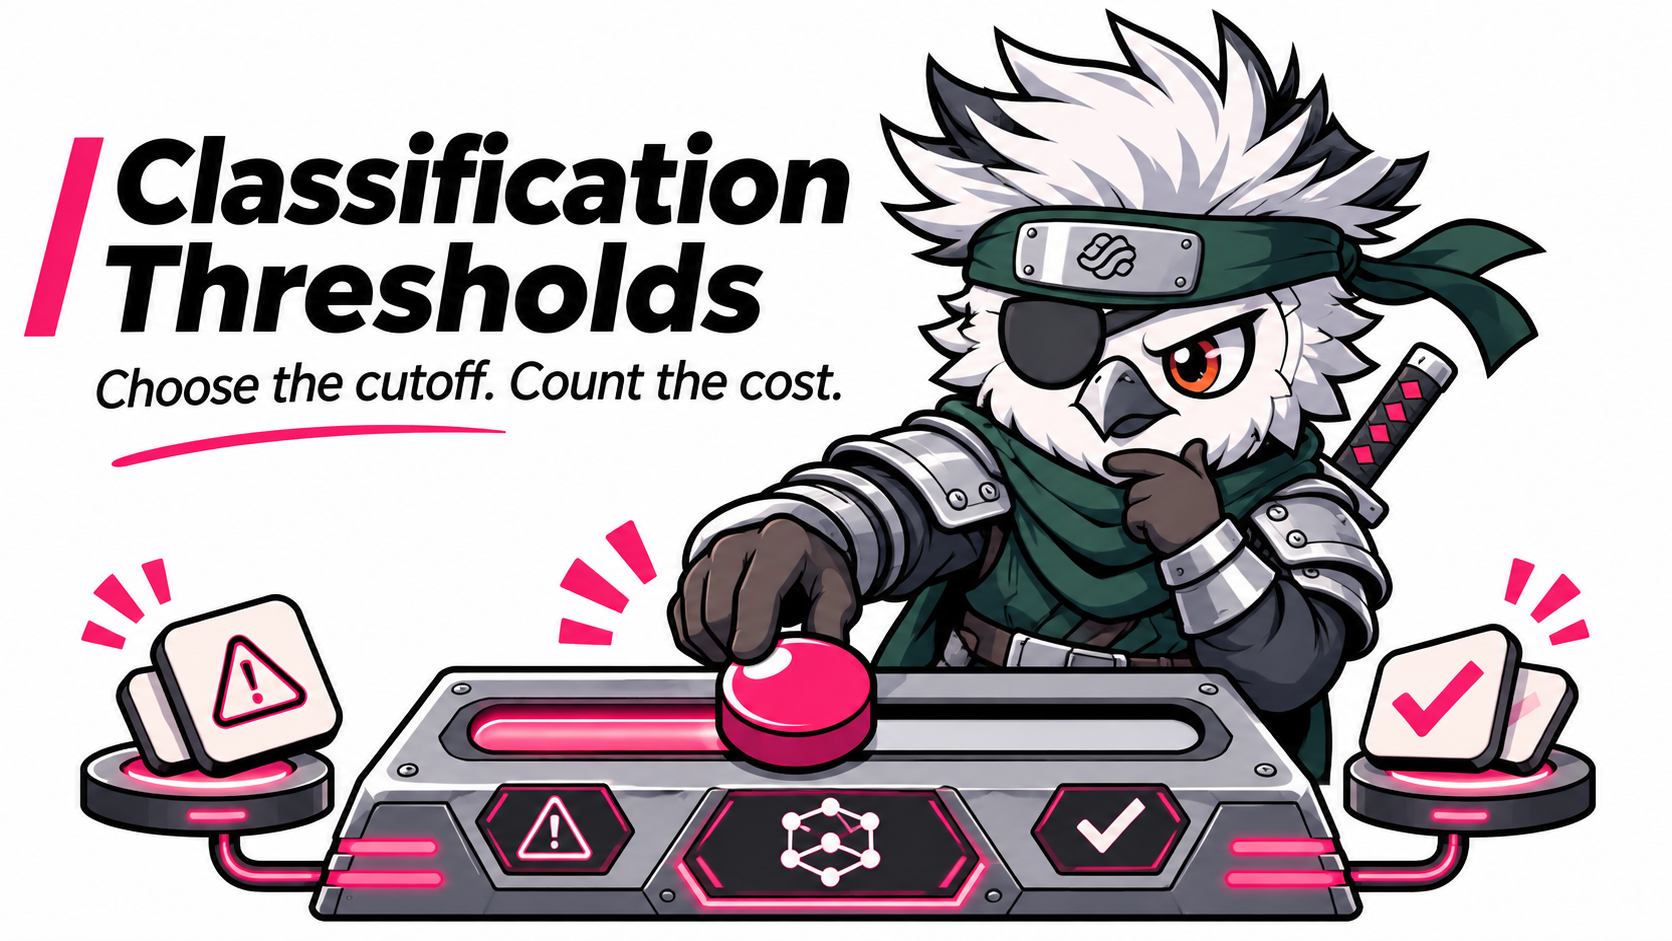

# Classification Threshold Tuning
### A hands-on lab from How to Learn Machine Learning

**Hey friends!** Today you are in charge of a model’s alert button. Turn the sensitivity up and you catch more positive cases—but someone has to review those extra alerts. Let’s see the trade-off for ourselves.

[Read the companion article](https://howtolearnmachinelearning.com/articles/classification-threshold-tuning/)

## Your mission 🦉
By the end, you will be able to explain a threshold, compare false alarms with missed cases, and choose a cutoff without peeking at test data.

**How to use this notebook:** run one code cell at a time with its play button or Shift+Enter. Read the output before moving on. A standard CPU runtime is enough. No dataset downloads or API keys are needed.

**The learning loop:** predict what will happen → run the code → explain the result in your own words.

Use NumPy, scikit-learn and Matplotlib (normally available in Colab). Tested with scikit-learn 1.8.0, NumPy 2.3.5 and Matplotlib 3.10.8. Outputs below are saved from that run; running a cell replaces them with your own results.

## Step 1 — Meet the decision rule
A case becomes an alert when its probability is **greater than or equal to** the cutoff. No retraining required.

**Predict:** a case has probability 0.30. Will it trigger an alert at 0.50? What about 0.20?

In [1]:
import sklearn
import matplotlib.pyplot as plt
print("scikit-learn", sklearn.__version__)
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score


probability = 0.30
for cutoff in [0.50, 0.20]:
    print(f"Score {probability:.2f}, cutoff {cutoff:.2f}: alert = {probability >= cutoff}")

scikit-learn 1.8.0
Score 0.30, cutoff 0.50: alert = False
Score 0.30, cutoff 0.20: alert = True


**Checkpoint:** False at 0.50, True at 0.20. We changed the decision, not the model’s score.

## Step 2 — Give each dataset one job
We generate 6,000 synthetic observations with an uncommon positive class. The random seed makes the example repeatable. Training teaches the model, validation chooses the threshold, and the test set checks the final choice.

These are independent synthetic rows. Real time series or repeated people/accounts need a split that respects their structure.

In [2]:
X, y = make_classification(
    n_samples=6000, n_features=12, n_informative=6,
    n_redundant=2, weights=[0.9, 0.1], flip_y=0.02,
    class_sep=1.0, random_state=42
)
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5,
    stratify=y_rest, random_state=42
)

print(f"Train: {len(y_train):,} | Validation: {len(y_val):,} | Test: {len(y_test):,}")
print(f"Training positive rate: {y_train.mean():.1%}")

Train: 3,600 | Validation: 1,200 | Test: 1,200
Training positive rate: 10.6%


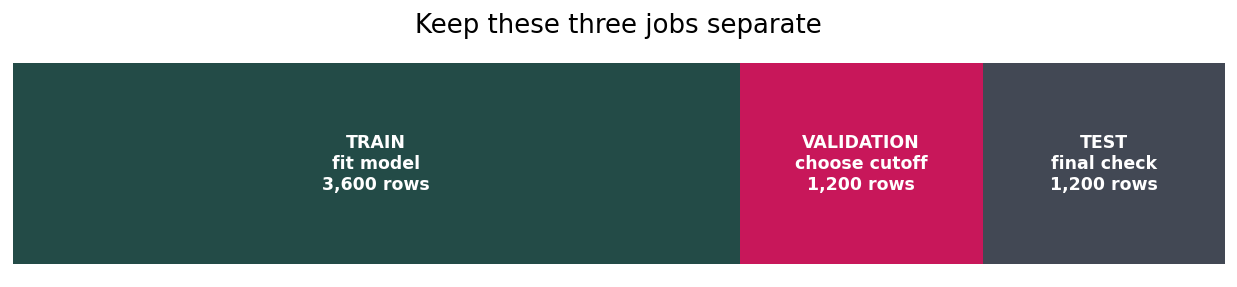

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.4))
start = 0
for size, label, color in [(len(y_train), 'TRAIN / fit model', '#234b47'),
                            (len(y_val), 'VALIDATION / choose cutoff', '#c8175a'),
                            (len(y_test), 'TEST / final check', '#424854')]:
    ax.barh(0, size, left=start, color=color, height=.7)
    ax.text(start+size/2, 0, label.replace(' / ', '\n')+f'\n{size:,} rows',
            ha='center', va='center', color='white', fontsize=10, weight='bold')
    start += size
ax.set_xlim(0, start); ax.axis('off')
ax.set_title('Keep these three jobs separate', fontsize=15, pad=12)
fig.tight_layout(); plt.show()

## Step 3 — Train once, get probabilities
The pipeline learns scaling from training data only, then fits logistic regression. Validation rows are never used to fit either step.

**Look for:** `predict_proba` returns probabilities, not final decisions. Labels are 0 and 1 here, so column 1 is the positive class. For other labels, check `model.classes_`.

In [4]:
model = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]

print("Class order:", model.classes_)
print("First five validation probabilities:", np.round(p_val[:5], 3))

Class order: [0 1]
First five validation probabilities: [0.012 0.543 0.    0.002 0.001]


## Step 4 — Put a price on mistakes
- **False positive (FP):** a false alarm; costs 1 unit.
- **False negative (FN):** a missed positive; costs 10 units.
- Correct decisions cost zero in this simplified example.

**Predict:** 4 false alarms and 2 missed cases cost how much? Work it out before running the next cell.

These are illustrative costs, not measured business values.

In [5]:
print("Mini-challenge answer:", 4 * 1 + 2 * 10, "cost units")

Mini-challenge answer: 24 cost units


### Your controls
You can change the two costs below. After changing them, rerun the validation steps that follow. Finish your experiments before opening the test results.

In [6]:
FALSE_POSITIVE_COST = 1.0
FALSE_NEGATIVE_COST = 10.0
assert np.isfinite([FALSE_POSITIVE_COST, FALSE_NEGATIVE_COST]).all()
assert FALSE_POSITIVE_COST >= 0 and FALSE_NEGATIVE_COST >= 0
assert FALSE_POSITIVE_COST + FALSE_NEGATIVE_COST > 0


### The scorekeeper
This helper counts the four outcomes, reports precision and recall, and adds up the cost. You can run it as-is on your first pass.

**Precision:** among flagged cases, how many are positive? **Recall:** among actual positives, how many did we catch? If no cases are flagged, precision is undefined; we display zero by convention.

In [7]:
def summarize(labels, probabilities, threshold):
    predictions = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold), "TN": int(tn), "FP": int(fp),
        "FN": int(fn), "TP": int(tp), "flagged": int(fp + tp),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "cost": float(FALSE_POSITIVE_COST * fp + FALSE_NEGATIVE_COST * fn)
    }


## Step 5 — Find the lowest validation cost
We try 101 cutoffs from 0 to 1. Ties go to the first minimum, which is the lower threshold. The selected cutoff is the best on this grid for this validation sample—not a universal optimum.

In [8]:
thresholds = np.linspace(0, 1, 101)
costs = np.array([summarize(y_val, p_val, t)["cost"] for t in thresholds])
best = float(thresholds[np.argmin(costs)])
print(f"Selected validation threshold: {best:.2f}")
print("Validation:", summarize(y_val, p_val, best))

Selected validation threshold: 0.19
Validation: {'threshold': 0.19, 'TN': 976, 'FP': 96, 'FN': 39, 'TP': 89, 'flagged': 185, 'precision': 0.4810810810810811, 'recall': 0.6953125, 'cost': 486.0}


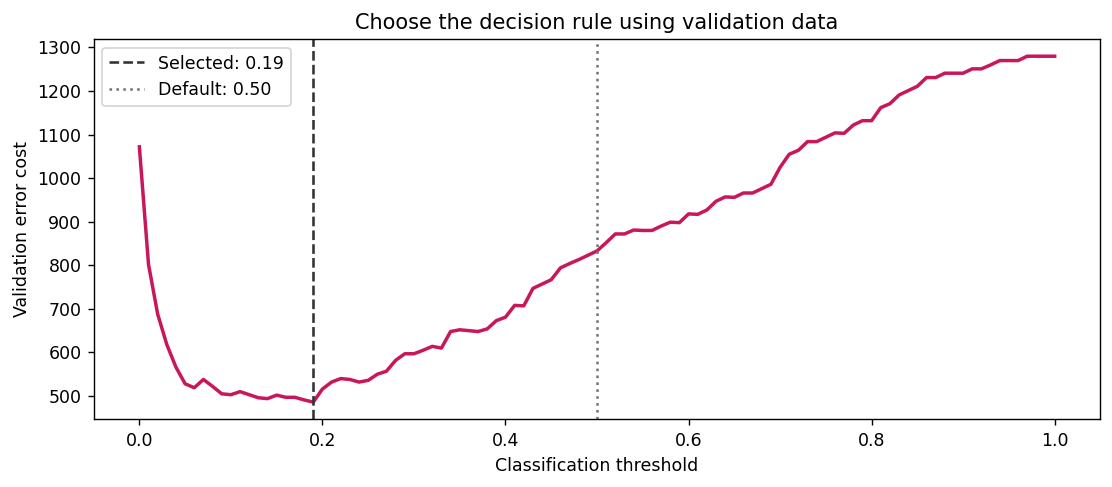

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresholds, costs, color="#c8175a", linewidth=2)
ax.axvline(best, color="#30343b", linestyle="--", label=f"Selected: {best:.2f}")
ax.axvline(0.5, color="#777777", linestyle=":", label="Default: 0.50")
ax.set(xlabel="Classification threshold", ylabel="Validation error cost",
       title="Choose the decision rule using validation data")
ax.legend()
fig.tight_layout()
plt.show()

**Read the chart:** the dashed line is the selected cutoff; the dotted line is 0.50. Lower on the vertical axis means less validation error cost.

## Step 6 — Take the controls
Change `TRY_THRESHOLD` below and rerun this cell. **Predict first:** what will happen to the number of alerts and missed cases if you lower the cutoff?

The figure compares your chosen cutoff with 0.50 on **validation data only**.

Cutoff 0.50: alerts=59, precision=0.780, recall=0.359
Cutoff 0.30: alerts=120, precision=0.608, recall=0.570


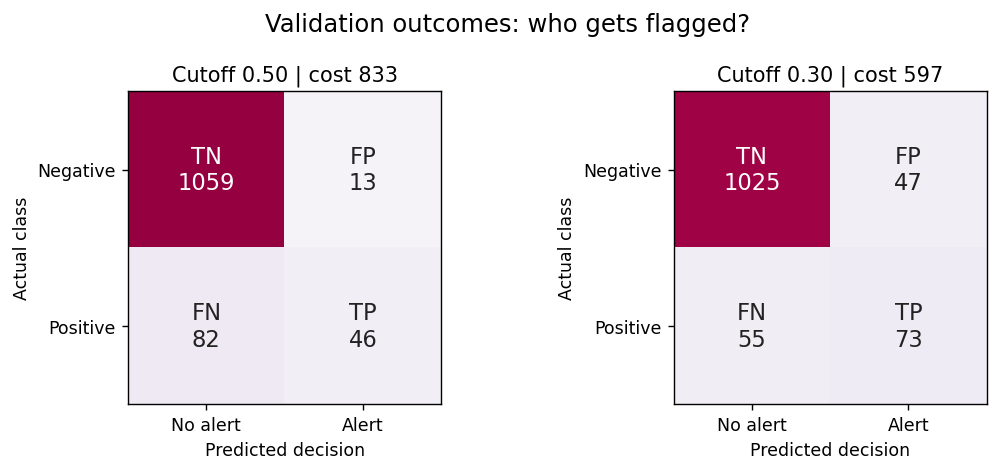

In [10]:
TRY_THRESHOLD = 0.30
assert 0 <= TRY_THRESHOLD <= 1
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, cutoff in zip(axes, [0.50, TRY_THRESHOLD]):
    result = summarize(y_val, p_val, cutoff)
    matrix = np.array([[result['TN'], result['FP']], [result['FN'], result['TP']]])
    ax.imshow(matrix, cmap='PuRd', vmin=0, vmax=len(y_val))
    for (row, col), value in np.ndenumerate(matrix):
        name = [['TN', 'FP'], ['FN', 'TP']][row][col]
        ax.text(col, row, f'{name}\n{value}', ha='center', va='center',
                color='white' if value > len(y_val)*.55 else '#222222', fontsize=13)
    ax.set_xticks([0,1], ['No alert','Alert']); ax.set_yticks([0,1], ['Negative','Positive'])
    ax.set_xlabel('Predicted decision'); ax.set_ylabel('Actual class')
    ax.set_title(f"Cutoff {cutoff:.2f} | cost {result['cost']:.0f}")
    print(f"Cutoff {cutoff:.2f}: alerts={result['flagged']}, precision={result['precision']:.3f}, recall={result['recall']:.3f}")
fig.suptitle('Validation outcomes: who gets flagged?', fontsize=14)
fig.tight_layout(); plt.show()

### Three mini-missions 🎯
1. Try cutoffs 0.10, 0.30 and 0.70. Which creates the largest review queue?
2. Change the FN cost to 1, then 5, then 10. Rerun Steps 4–5 and write down each chosen threshold and validation cost. Costs measured under different cost ratios are different objectives—do not compare their totals as if they were identical.
3. Imagine only 100 validation cases can be reviewed. Does the minimum-cost rule fit that capacity?

**Answers to check your reasoning:** lowering the cutoff cannot reduce alerts or recall on the same data. Precision need not change monotonically. More costly misses favor avoiding false negatives, but finite samples and tied optima can leave the selected threshold unchanged. A capacity limit needs to be included in the decision rule.

Restore the costs to 1 and 10 and rerun Steps 4–5 if you want to reproduce the article's default result.

## Step 7 — Final check: lock the threshold 🔒
Finish all validation exploration before running the next cell. We compare the predeclared 0.50 baseline with the validation-selected cutoff on the test set.

**Pause:** can you explain why changing the threshold *after* viewing test results would make those results optimistic? You would be using the test set to make a development decision. Use fresh independent evaluation data if you continue selecting based on these results.

In [11]:
locked_threshold = best
p_test = model.predict_proba(X_test)[:, 1]
for threshold in [0.5, locked_threshold]:
    result = summarize(y_test, p_test, threshold)
    print(f"t={threshold:.2f} FP={result['FP']} FN={result['FN']} "
          f"precision={result['precision']:.3f} recall={result['recall']:.3f} "
          f"cost={result['cost']:.0f} flagged={result['flagged']}")

t=0.50 FP=25 FN=72 precision=0.688 recall=0.433 cost=745 flagged=80
t=0.19 FP=112 FN=43 precision=0.429 recall=0.661 cost=542 flagged=196


### Read the result like a practitioner
With the default costs in the tested environment, cutoff **0.19** reduces test cost from **745 to 542**. Missed cases fall from **72 to 43**, while false alarms rise from **25 to 112**. The review queue grows from **80 to 196**.

**Final challenge:** would you deploy it if the team could review only 100 cases? Explain which assumption in the cost-only objective needs to change.

The improvement is specific to this example. It is not a promise for another dataset. Saved test outputs document the example; they should not be used as a target when experimenting with validation settings.

## You made it! 🦉 Keep these habits
- Before opening the test set, compare validation choices for cost ratios 1:1, 1:5 and 1:10. Explain why the review queue changes.
- If reviewers can handle only a fixed number of cases, the cost objective is incomplete: include capacity in the decision rule.
- Random splits suit these independent synthetic rows. Use time-aware or group-aware evaluation when real data require it.
- Changing a threshold does not improve probability calibration. Re-fitting the model can change its scores and require a new threshold.
- The theoretical cutoff `C_FP / (C_FP + C_FN)` assumes calibrated probabilities for the deployment population, constant error costs and zero cost for correct decisions. It need not match a finite-sample validation optimum.

[Probability calibration tutorial](https://howtolearnmachinelearning.com/articles/probability-calibration-python/) · [Model evaluation guide](https://howtolearnmachinelearning.com/articles/evaluating-machine-learning-models/)

Want a learning plan? [Get the free 90-day ML roadmap](https://how-to-learn-machine-learning.kit.com/7a25f667cb).

Reference: [scikit-learn threshold tuning documentation](https://scikit-learn.org/stable/modules/classification_threshold.html).